In [ ]:
#Detección de la onda P en validación con STA/LTA, se usa el canal Z filtrado.
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import leer_metadata, cargar, armar_split
from src.dsp_filters import FS, filtrar
from src.detection import sta_lta, primer_cruce

df = leer_metadata()
df['split'] = armar_split(df)['split'].values
#snr_db trae la SNR de los tres canales como texto, se toma la del canal Z
df['snr_z'] = df['snr_db'].str.strip('[]').str.split().str[2].astype(float)
val = df[df['split'] == 'val']
sismos_val = val[val['trace_category'] == 'earthquake_local']
ruido_val = val[val['trace_category'] == 'noise']

#Se descartan las trazas de ruido con desvío en canal Z menor a esto:
MUERTA = 0.1
#Un pick es correcto si cae a menos de 0.5 s de la P marcada
TOLERANCIA = int(0.5 * FS)

def canal_z(fila):
    return cargar(fila.trace_name, fila.chunk)[:, 2].astype(float)

len(sismos_val), len(ruido_val)

(43174, 23543)

## STA/LTA

STA es la energía promedio de los últimos 0.5 s y LTA la de los últimos 5 s. Cuando llega la P, la STA sube antes que la LTA y el cociente se dispara. El pick es la primera muestra en la que el cociente supera el umbral.

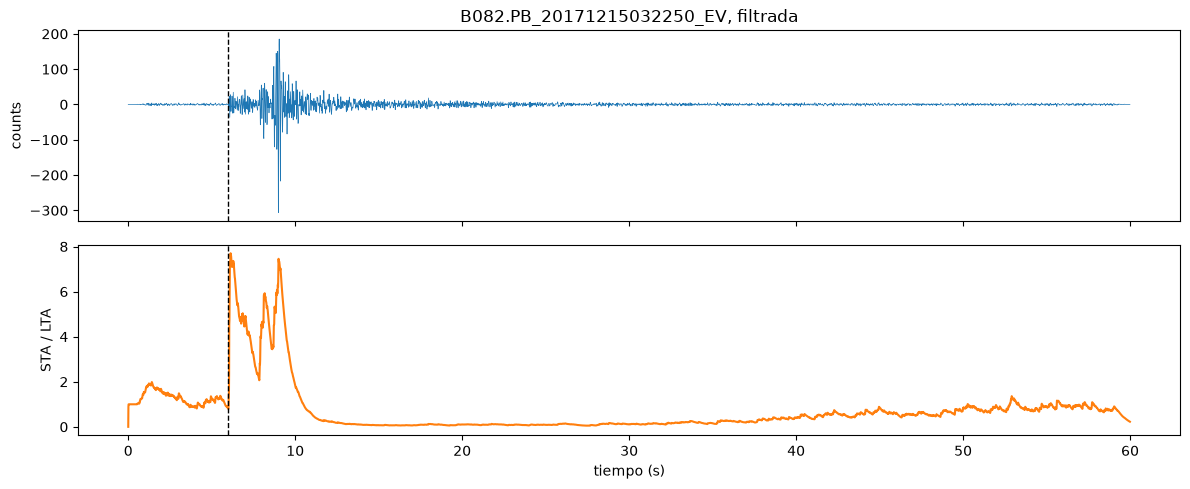

In [2]:
ej = sismos_val.sample(1, random_state=2).iloc[0]
zf = filtrar(canal_z(ej))
t = np.arange(len(zf)) / FS

fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axs[0].plot(t, zf, lw=0.5)
axs[0].set_ylabel('counts')
axs[0].set_title(f"{ej['trace_name']}, filtrada")
axs[1].plot(t, sta_lta(zf), color='C1')
axs[1].set_ylabel('STA / LTA')
axs[1].set_xlabel('tiempo (s)')
#Se marca la llegada de la P
for ax in axs:
    ax.axvline(ej['p_arrival_sample'] / FS, color='k', ls='--', lw=1)
plt.tight_layout()

### Barrido del umbral

Se usan 2000 sismos y 2000 trazas de ruido de validación. En un sismo la detección es correcta si el primer cruce cae a menos de 0.5 s de la P, si cruza antes o mucho después cuenta como error. En el ruido, cualquier cruce es una falsa alarma.

Para cada largo de LTA se toma el umbral más bajo que da a lo sumo 5 % de falsas alarmas.

In [3]:
N_VAL = 2000
UMBRALES = np.arange(2, 10.01, 0.25)
muestra_s = sismos_val.sample(N_VAL, random_state=0)
muestra_r = ruido_val.sample(N_VAL, random_state=0)

#Se cargan y filtran las trazas una sola vez
zf_s = [filtrar(canal_z(fila)) for fila in muestra_s.itertuples()]
zf_r = []
for fila in muestra_r.itertuples():
    z = canal_z(fila)
    if z.std() >= MUERTA:
        zf_r.append(filtrar(z))
p_s = muestra_s['p_arrival_sample'].to_numpy().astype(int)
print('Ruido muerto descartado:', N_VAL - len(zf_r))

def barrer(lta):
    #Para cada umbral se guarda el pick de cada sismo y si cada traza de ruido dispara
    picks = np.full((len(zf_s), len(UMBRALES)), np.nan)
    for i, zf in enumerate(zf_s):
        c = sta_lta(zf, lta=lta)
        for j, u in enumerate(UMBRALES):
            pk = primer_cruce(c, u)
            if pk is not None:
                picks[i, j] = pk
    #En el ruido alcanza con el máximo después del primer segundo
    maximos = np.array([sta_lta(zf, lta=lta)[FS:].max() for zf in zf_r])
    acierto = np.abs(picks - p_s[:, None]) <= TOLERANCIA
    falsas = (maximos[:, None] > UMBRALES).mean(axis=0) * 100
    return picks, acierto, falsas

resultados = {segundos: barrer(segundos * FS) for segundos in [3, 5, 10]}

filas = []
for segundos, (_, acierto, falsas) in resultados.items():
    j = np.flatnonzero(falsas <= 5)[0]
    filas.append({'LTA (s)': segundos, 'umbral': UMBRALES[j],
                  'detectados (%)': acierto[:, j].mean() * 100, 'falsas alarmas (%)': falsas[j]})
pd.DataFrame(filas).round(1)

Ruido muerto descartado: 2


,LTA (s),umbral,detectados (%),falsas alarmas (%)
0,3,4.0,82.5,4.5
1,5,5.5,83.2,4.9
2,10,8.0,67.2,4.6


Se elige LTA de 5 s, que es `LTA` en `src/detection.py`.

Umbral 5.5: detectados 83.2 %, falsas alarmas 4.9 %


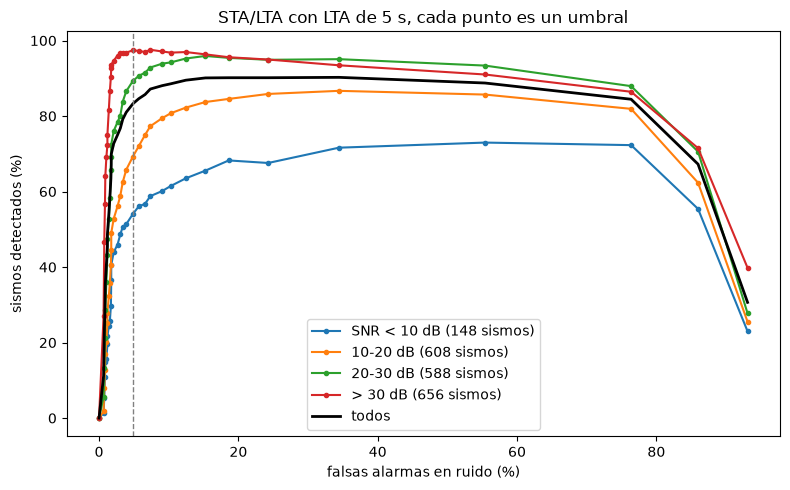

In [4]:
picks, acierto, falsas = resultados[5]
J = np.flatnonzero(falsas <= 5)[0]
UMBRAL = UMBRALES[J]
print(f'Umbral {UMBRAL}: detectados {acierto[:, J].mean() * 100:.1f} %, falsas alarmas {falsas[J]:.1f} %')

#Grupos de SNR del canal Z
GRUPOS = [(-np.inf, 10, 'SNR < 10 dB'), (10, 20, '10-20 dB'), (20, 30, '20-30 dB'), (30, np.inf, '> 30 dB')]
snr_s = muestra_s['snr_z'].to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
for bajo, alto, nombre in GRUPOS:
    sel = (snr_s >= bajo) & (snr_s < alto)
    ax.plot(falsas, acierto[sel].mean(axis=0) * 100, marker='.', label=f'{nombre} ({sel.sum()} sismos)')
ax.plot(falsas, acierto.mean(axis=0) * 100, color='k', lw=2, label='todos')
ax.axvline(falsas[J], color='0.5', ls='--', lw=1)
ax.set_xlabel('falsas alarmas en ruido (%)')
ax.set_ylabel('sismos detectados (%)')
ax.set_title('STA/LTA con LTA de 5 s, cada punto es un umbral')
ax.legend()
plt.tight_layout()

Error del pick con el umbral elegido, en segundos. Negativo quiere decir que disparó antes de la P.

Sin pick: 6.9 %
Antes de la P (más de 0.5 s): 0.3 %
A menos de 0.5 s: 83.2 %
Después (más de 0.5 s): 9.6 %


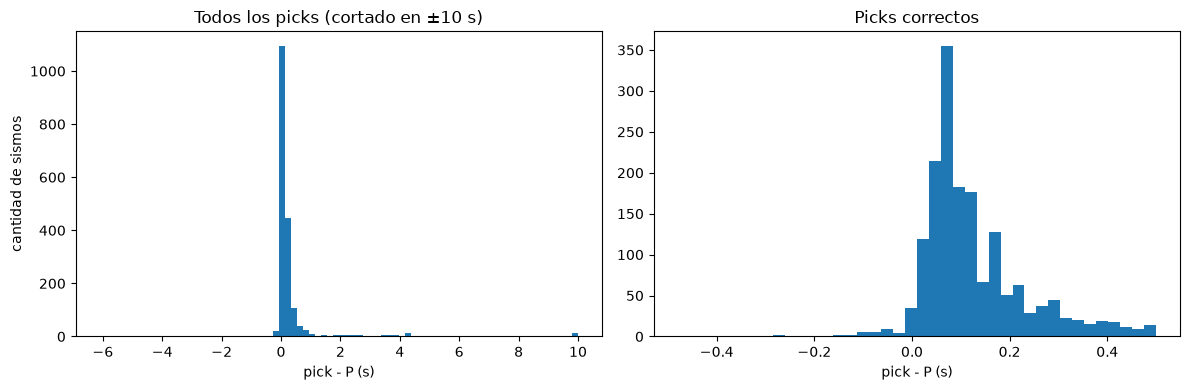

In [5]:
error = (picks[:, J] - p_s) / FS
sin_pick = np.isnan(error).mean() * 100
error = error[~np.isnan(error)]
print(f'Sin pick: {sin_pick:.1f} %')
print(f'Antes de la P (más de 0.5 s): {(error < -0.5).sum() / N_VAL * 100:.1f} %')
print(f'A menos de 0.5 s: {(np.abs(error) <= 0.5).sum() / N_VAL * 100:.1f} %')
print(f'Después (más de 0.5 s): {(error > 0.5).sum() / N_VAL * 100:.1f} %')

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(np.clip(error, -10, 10), bins=80)
axs[0].set_title('Todos los picks (cortado en ±10 s)')
axs[1].hist(error[np.abs(error) <= 0.5], bins=40)
axs[1].set_title('Picks correctos')
for ax in axs:
    ax.set_xlabel('pick - P (s)')
axs[0].set_ylabel('cantidad de sismos')
plt.tight_layout()

Cuando dispara bien, el pick llega en general entre 0 y 0.2 s después de la P, por el retardo del filtro causal y de la STA. Casi nunca dispara antes de la P. Los errores son sobre todo sismos sin pick (6.9 %) o con el pick más tarde (9.6 %), y como se ve en la curva, los que menos se detectan son los de SNR baja.

## Resultado por SNR

Detectados (%) con LTA de 5 s y el umbral elegido.

In [6]:
tabla = {}
for bajo, alto, nombre in GRUPOS + [(-np.inf, np.inf, 'todos')]:
    sel = (snr_s >= bajo) & (snr_s < alto)
    tabla[nombre] = {'detectados (%)': acierto[sel, J].mean() * 100, 'sismos': int(sel.sum())}
pd.DataFrame(tabla).T.round(1)

,detectados (%),sismos
SNR < 10 dB,54.1,148.0
10-20 dB,69.2,608.0
20-30 dB,89.3,588.0
> 30 dB,97.4,656.0
todos,83.2,2000.0


El detector del proyecto es el STA/LTA, con LTA de 5 s y umbral 5.5 (`UMBRAL_STA_LTA` en `src/detection.py`). Detecta el 83 % de los sismos de validación con 5 % de falsas alarmas, y baja al 54 % cuando la SNR es menor a 10 dB.

El test queda para la evaluación final.